<a href="https://colab.research.google.com/github/karani123-Jeswanth/192472012_DSA0402-FODS/blob/main/Experiments-21--40.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import scipy.stats as stats
import pandas as pd

np.random.seed(42)
pd.DataFrame({'concentration': np.random.normal(50.0, 8.0, 200)}).to_csv('rare_elements.csv', index=False)

data = pd.read_csv('rare_elements.csv')['concentration'].to_numpy()

sample_size = 50
confidence_level = 0.95
precision = 2.5

sample = np.random.choice(data, size=min(sample_size, len(data)), replace=False)
point_est = np.mean(sample)
se = stats.sem(sample)
margin = se * stats.t.ppf((1 + confidence_level) / 2, len(sample) - 1)

print(f"Point Estimate (Sample Mean): {point_est:.4f}")
print(f"{confidence_level*100:.0f}% Confidence Interval: ({point_est - margin:.4f}, {point_est + margin:.4f})")
print(f"Actual Margin of Error: ±{margin:.4f} | Meets precision ({precision})? {margin <= precision}")

Point Estimate (Sample Mean): 49.3140
95% Confidence Interval: (46.9928, 51.6351)
Actual Margin of Error: ±2.3212 | Meets precision (2.5)? True


In [3]:
import pandas as pd
import scipy.stats as stats

pd.DataFrame({'rating': [5, 4, 5, 3, 4, 5, 2, 4, 5, 4, 3, 5, 4, 4, 5]}).to_csv('customer_reviews.csv', index=False)

df = pd.read_csv('customer_reviews.csv')
ratings = df['rating'].dropna()

mean_rating = ratings.mean()
sem_rating = stats.sem(ratings)
ci_low, ci_high = stats.t.interval(0.95, df=len(ratings)-1, loc=mean_rating, scale=sem_rating)

print(f"Mean Rating: {mean_rating:.2f}")
print(f"95% Confidence Interval: ({ci_low:.2f}, {ci_high:.2f})")

Mean Rating: 4.13
95% Confidence Interval: (3.63, 4.64)


T-statistic: 3.9798, P-value: 0.000194


/tmp/ipykernel_589/2054527944.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([control, treatment], labels=['Control (Placebo)', 'Treatment (Drug)'])


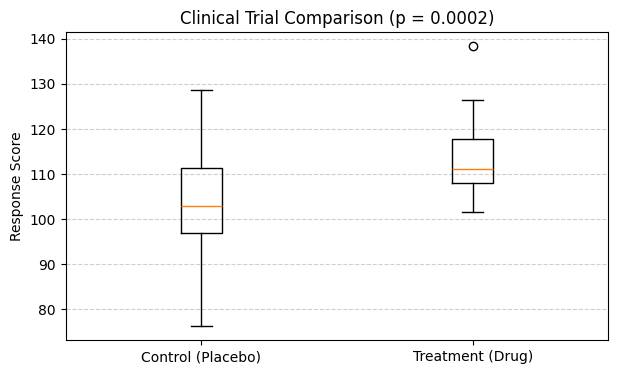

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(10)
control = np.random.normal(100, 12, 30)
treatment = np.random.normal(112, 11, 30)

t_stat, p_val = stats.ttest_ind(treatment, control)
print(f"T-statistic: {t_stat:.4f}, P-value: {p_val:.6f}")

plt.figure(figsize=(7, 4))
plt.boxplot([control, treatment], labels=['Control (Placebo)', 'Treatment (Drug)'])
plt.title(f'Clinical Trial Comparison (p = {p_val:.4f})')
plt.ylabel('Response Score')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

In [5]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

X = np.array([
    [98.6, 1, 2], [99.0, 2, 3], [98.4, 0, 1], [99.2, 1, 2],
    [101.5, 8, 7], [102.0, 9, 8], [101.0, 7, 8], [102.4, 8, 9]
])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

k = 3
new_patient = [[101.8, 8, 7]]

model = KNeighborsClassifier(n_neighbors=k)
model.fit(X, y)
pred = model.predict(new_patient)[0]
print("Prediction:", "Condition Present (1)" if pred == 1 else "No Condition (0)")

Prediction: Condition Present (1)


In [6]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

iris = load_iris()
clf = DecisionTreeClassifier(random_state=42)
clf.fit(iris.data, iris.target)

new_flower = [[5.1, 3.5, 1.4, 0.2]]
pred_idx = clf.predict(new_flower)[0]
print("Predicted Iris Species:", iris.target_names[pred_idx])

Predicted Iris Species: setosa


In [7]:
import numpy as np
from sklearn.linear_model import LinearRegression

X = np.array([
    [1200, 2, 1], [1500, 3, 2], [1800, 3, 2],
    [2200, 4, 3], [2600, 4, 3], [3000, 5, 3]
])
y = np.array([200000, 275000, 320000, 410000, 480000, 560000])

reg = LinearRegression()
reg.fit(X, y)

new_house = [[2400, 4, 3]]
pred_price = reg.predict(new_house)[0]
print(f"Predicted House Price: ${pred_price:,.2f}")

Predicted House Price: $444,976.30


In [8]:
import numpy as np
from sklearn.linear_model import LogisticRegression

X = np.array([
    [600, 24], [550, 18], [700, 36], [480, 12],
    [120, 1],  [90, 2],   [150, 1],  [110, 3]
])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

clf = LogisticRegression()
clf.fit(X, y)

new_customer = [[130, 2]]
pred = clf.predict(new_customer)[0]
prob = clf.predict_proba(new_customer)[0][1]
print(f"Churn Prediction: {'Will Churn (1)' if pred == 1 else 'Will Stay (0)'} (Churn Prob: {prob:.2%})")

Churn Prediction: Will Churn (1) (Churn Prob: 100.00%)


In [9]:
import numpy as np
from sklearn.cluster import KMeans

X = np.array([
    [200, 2], [250, 3], [300, 2],
    [1200, 15], [1400, 18], [1300, 16],
    [3500, 30], [4000, 35], [3800, 32]
])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X)

new_customer = [[1350, 17]]
segment = kmeans.predict(new_customer)[0]
print(f"Assigned Customer Segment: Cluster {segment}")

Assigned Customer Segment: Cluster 0


In [10]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
target_col = 'target'

X_train, X_test, y_train, y_test = train_test_split(df[features], df[target_col], test_size=0.3, random_state=42)

model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred):.4f}")

Accuracy : 0.9357
Precision: 0.9619
Recall   : 0.9352
F1-Score : 0.9484


In [11]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor

X = np.array([
    [15, 1, 3, 2], [25, 2, 3, 1], [40, 3, 2, 2],
    [55, 4, 2, 1], [70, 6, 1, 1], [90, 8, 1, 1]
])
y = np.array([42000, 35000, 26000, 20000, 13000, 8500])
feature_names = ['Mileage (k)', 'Age (yrs)', 'Brand Code', 'Engine Code']

reg = DecisionTreeRegressor(max_depth=3, random_state=42)
reg.fit(X, y)

sample = np.array([[45, 3, 2, 2]])
pred_price = reg.predict(sample)[0]
print(f"Predicted Car Price: ${pred_price:,.2f}")

tree = reg.tree_
node_indicator = reg.decision_path(sample)
leaf_id = reg.apply(sample)[0]
node_index = node_indicator.indices[node_indicator.indptr[0]:node_indicator.indptr[1]]

print("\nDecision Path:")
for node_id in node_index:
    if leaf_id == node_id:
        print(f"  Leaf node {node_id} -> Predicted Price = ${pred_price:,.2f}")
    else:
        feat = feature_names[tree.feature[node_id]]
        thresh = tree.threshold[node_id]
        op = "<=" if sample[0, tree.feature[node_id]] <= thresh else ">"
        print(f"  Node {node_id}: ({feat} = {sample[0, tree.feature[node_id]]}) {op} {thresh:.2f}")

Predicted Car Price: $26,000.00

Decision Path:
  Node 0: (Mileage (k) = 45) <= 47.50
  Node 1: (Mileage (k) = 45) > 32.50
  Leaf node 5 -> Predicted Price = $26,000.00


In [12]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.DataFrame({
    'customer_id': range(1, 11),
    'total_spend': [120, 150, 800, 950, 2400, 2600, 140, 880, 2500, 200],
    'pages_viewed': [5, 7, 20, 22, 45, 50, 6, 19, 48, 8],
    'age': [22, 25, 35, 38, 42, 45, 24, 36, 44, 27]
})

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['total_spend', 'pages_viewed', 'age']])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['segment'] = kmeans.fit_predict(X_scaled)
print(df)

   customer_id  total_spend  pages_viewed  age  segment
0            1          120             5   22        1
1            2          150             7   25        1
2            3          800            20   35        0
3            4          950            22   38        0
4            5         2400            45   42        2
5            6         2600            50   45        2
6            7          140             6   24        1
7            8          880            19   36        0
8            9         2500            48   44        2
9           10          200             8   27        1


In [13]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

size = np.array([900, 1200, 1500, 1800, 2100, 2400, 2700, 3000, 3300, 3600]).reshape(-1, 1)
price = np.array([150000, 195000, 240000, 285000, 330000, 375000, 420000, 465000, 510000, 560000])

X_train, X_test, y_train, y_test = train_test_split(size, price, test_size=0.3, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
preds = model.predict(X_test)

print(f"Slope: {model.coef_[0]:.2f}, Intercept: {model.intercept_:.2f}")
print(f"R² Score: {r2_score(y_test, preds):.4f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test, preds)):,.2f}")

Slope: 151.32, Intercept: 12772.28
R² Score: 0.9999
RMSE: $1,394.07


In [14]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.DataFrame({
    'engine_size': [1.5, 2.0, 2.5, 3.0, 1.8, 3.5, 2.2, 4.0],
    'horsepower': [120, 160, 200, 260, 140, 310, 180, 360],
    'mpg': [35, 30, 26, 22, 32, 19, 28, 16],
    'price': [20000, 26000, 32000, 41000, 23000, 49000, 29000, 58000]
})

features = ['engine_size', 'horsepower', 'mpg']
X_train, X_test, y_train, y_test = train_test_split(df[features], df['price'], test_size=0.25, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
preds = model.predict(X_test)

print(f"R² Score: {r2_score(y_test, preds):.4f} | MAE: ${mean_absolute_error(y_test, preds):,.2f}")
for feat, coef in zip(features, model.coef_):
    print(f"  {feat}: coefficient = {coef:.2f}")

R² Score: 0.9986 | MAE: $384.17
  engine_size: coefficient = 5709.83
  horsepower: coefficient = 143.92
  mpg: coefficient = 580.34


In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = pd.DataFrame({
    'age': [34, 45, 52, 29, 60, 41, 55, 38, 48, 63, 31, 50],
    'bp': [120, 140, 150, 118, 160, 130, 145, 125, 138, 165, 122, 142],
    'cholesterol': [180, 220, 240, 170, 260, 195, 230, 185, 210, 270, 175, 215],
    'outcome': ['Good', 'Bad', 'Bad', 'Good', 'Bad', 'Good', 'Bad', 'Good', 'Good', 'Bad', 'Good', 'Bad']
})

X = df[['age', 'bp', 'cholesterol']]
y = df['outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)

print("Test Predictions:", list(zip(y_test, y_pred)))
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, pos_label='Good', zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, pos_label='Good', zero_division=0):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred, pos_label='Good', zero_division=0):.4f}")

Test Predictions: [('Good', 'Good'), ('Bad', 'Bad'), ('Good', 'Good'), ('Good', 'Bad')]
Accuracy : 0.7500
Precision: 1.0000
Recall   : 0.6667
F1-Score : 0.8000


In [16]:
import pandas as pd
from sklearn.cluster import KMeans

transactions = pd.DataFrame({
    'customer_id': [1, 2, 3, 4, 5, 6, 7, 8, 9],
    'amount_spent': [25, 30, 20, 150, 175, 160, 500, 540, 480],
    'visit_frequency': [1, 2, 1, 6, 7, 6, 15, 16, 14]
})

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
transactions['cluster'] = kmeans.fit_predict(transactions[['amount_spent', 'visit_frequency']])
print(transactions.groupby('cluster')[['amount_spent', 'visit_frequency']].mean())
print("\nSegmented Customers:\n", transactions)

         amount_spent  visit_frequency
cluster                               
0          161.666667         6.333333
1          506.666667        15.000000
2           25.000000         1.333333

Segmented Customers:
    customer_id  amount_spent  visit_frequency  cluster
0            1            25                1        2
1            2            30                2        2
2            3            20                1        2
3            4           150                6        0
4            5           175                7        0
5            6           160                6        0
6            7           500               15        1
7            8           540               16        1
8            9           480               14        1


In [17]:
import pandas as pd

pd.DataFrame({
    'date': pd.date_range('2026-01-01', periods=10, freq='B'),
    'close': [150.2, 152.5, 149.8, 155.0, 153.4, 158.1, 157.0, 160.5, 159.2, 162.0]
}).to_csv('stock_prices.csv', index=False)

df = pd.read_csv('stock_prices.csv')
returns = df['close'].pct_change().dropna()

print(f"Closing Price Std Dev: {df['close'].std():.2f}")
print(f"Price Range (Max - Min): ${df['close'].max() - df['close'].min():.2f}")
print(f"Daily Return Volatility (Std Dev): {returns.std():.2%}")

Closing Price Std Dev: 4.26
Price Range (Max - Min): $12.20
Daily Return Volatility (Std Dev): 1.95%


Pearson Correlation Coefficient: 0.9950


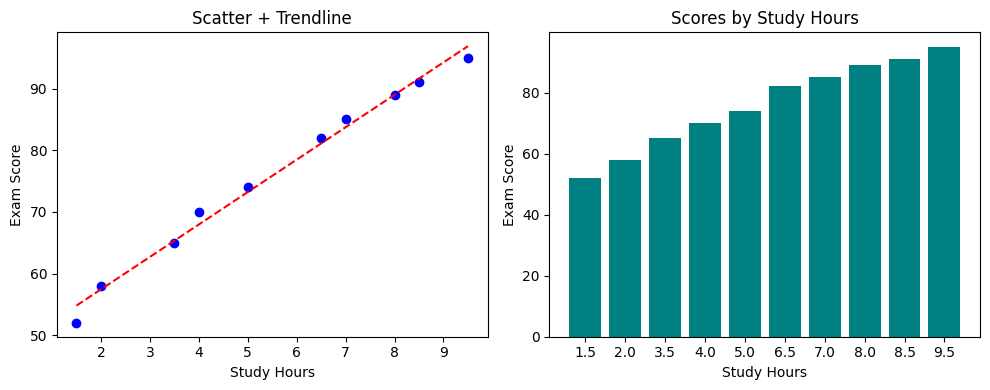

In [18]:
import numpy as np
import matplotlib.pyplot as plt

study_hours = np.array([1.5, 2.0, 3.5, 4.0, 5.0, 6.5, 7.0, 8.0, 8.5, 9.5])
exam_scores = np.array([52, 58, 65, 70, 74, 82, 85, 89, 91, 95])

corr = np.corrcoef(study_hours, exam_scores)[0, 1]
print(f"Pearson Correlation Coefficient: {corr:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(study_hours, exam_scores, color='blue')
m, b = np.polyfit(study_hours, exam_scores, 1)
axes[0].plot(study_hours, m * study_hours + b, color='red', linestyle='--')
axes[0].set_title('Scatter + Trendline')
axes[0].set_xlabel('Study Hours')
axes[0].set_ylabel('Exam Score')

axes[1].bar(study_hours.astype(str), exam_scores, color='teal')
axes[1].set_title('Scores by Study Hours')
axes[1].set_xlabel('Study Hours')
axes[1].set_ylabel('Exam Score')

plt.tight_layout()
plt.show()

In [19]:
import pandas as pd
import numpy as np

np.random.seed(42)
temps_df = pd.DataFrame({
    'CityA': np.random.normal(25, 2.0, 365),
    'CityB': np.random.uniform(5, 40, 365),
    'CityC': np.random.normal(18, 5.5, 365)
})

means = temps_df.mean()
stds = temps_df.std()
ranges = temps_df.max() - temps_df.min()

print("Mean Temperature per City:\n", means.round(2))
print("\nStandard Deviation per City:\n", stds.round(2))
print(f"\nHighest Temperature Range: {ranges.idxmax()} ({ranges.max():.2f})")
print(f"Most Consistent Temperature (Lowest Std Dev): {stds.idxmin()} ({stds.min():.2f})")

Mean Temperature per City:
 CityA    25.02
CityB    22.55
CityC    17.74
dtype: float64

Standard Deviation per City:
 CityA     1.90
CityB    10.13
CityC     5.37
dtype: float64

Highest Temperature Range: CityB (34.83)
Most Consistent Temperature (Lowest Std Dev): CityA (1.90)


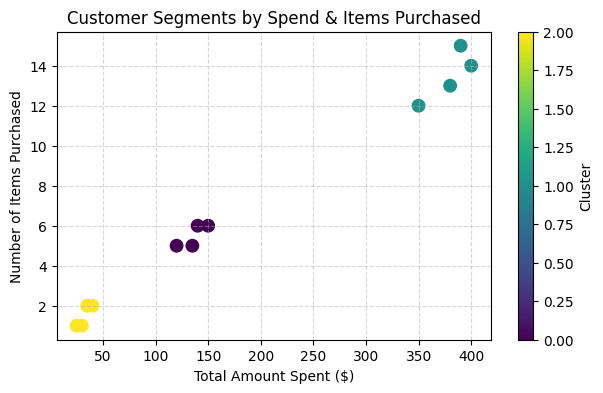

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.DataFrame({
    'customer_id': range(1, 13),
    'total_amount': [25, 35, 40, 120, 140, 135, 350, 400, 380, 30, 150, 390],
    'items_purchased': [1, 2, 2, 5, 6, 5, 12, 14, 13, 1, 6, 15]
})

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(df[['total_amount', 'items_purchased']])

plt.figure(figsize=(7, 4))
scatter = plt.scatter(df['total_amount'], df['items_purchased'], c=df['cluster'], cmap='viridis', s=80)
plt.title('Customer Segments by Spend & Items Purchased')
plt.xlabel('Total Amount Spent ($)')
plt.ylabel('Number of Items Purchased')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Top 5 Goal Scorers:
      name  goals
2  Oliver     22
0    Liam     18
6    Levi     15
4   Mateo     12
1    Noah     10

Top 5 Highest Salaries:
      name  weekly_salary
2  Oliver         140000
5   Lucas         120000
1    Noah         110000
4   Mateo         105000
0    Liam          95000

Average Age: 26.88
Players Above Average Age: ['Noah', 'Oliver', 'Mateo', 'Lucas', 'Leo']


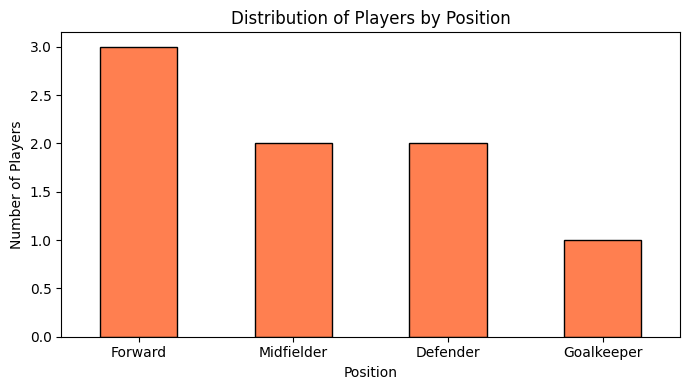

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

players_data = pd.DataFrame({
    'name': ['Liam', 'Noah', 'Oliver', 'Elijah', 'Mateo', 'Lucas', 'Levi', 'Leo'],
    'age': [22, 28, 31, 24, 27, 33, 21, 29],
    'position': ['Forward', 'Midfielder', 'Forward', 'Defender', 'Midfielder', 'Defender', 'Forward', 'Goalkeeper'],
    'goals': [18, 10, 22, 4, 12, 5, 15, 0],
    'weekly_salary': [95000, 110000, 140000, 75000, 105000, 120000, 85000, 70000]
})
players_data.to_csv('soccer_players.csv', index=False)

df = pd.read_csv('soccer_players.csv')

print("Top 5 Goal Scorers:\n", df.nlargest(5, 'goals')[['name', 'goals']])
print("\nTop 5 Highest Salaries:\n", df.nlargest(5, 'weekly_salary')[['name', 'weekly_salary']])

avg_age = df['age'].mean()
above_avg = df[df['age'] > avg_age]['name'].tolist()
print(f"\nAverage Age: {avg_age:.2f}")
print("Players Above Average Age:", above_avg)

plt.figure(figsize=(7, 4))
df['position'].value_counts().plot(kind='bar', color='coral', edgecolor='black')
plt.title('Distribution of Players by Position')
plt.xlabel('Position')
plt.ylabel('Number of Players')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()